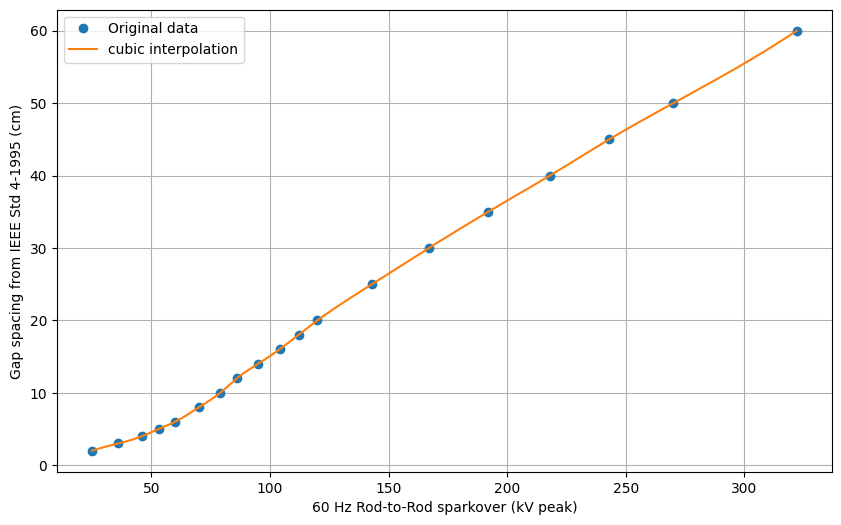

x_test [kV peak]: [ 43.22628958 103.74309499 208.9270663 ]
y_test [cm]: [ 3.67019059 15.93867342 38.23867045]


In [9]:
# Comments in English only

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d


class SparkoverGapInterpolator:
    def __init__(self, x_kv_peak: np.ndarray, y_gap_cm: np.ndarray,
                 x_label: str, y_label: str, kind: str = "cubic"):
        # Store labels
        self.x_label = x_label
        self.y_label = y_label

        # Store data as float arrays
        self.x = np.array(x_kv_peak, dtype=float)
        self.y = np.array(y_gap_cm, dtype=float)

        # Basic validation
        if self.x.ndim != 1 or self.y.ndim != 1:
            raise ValueError("x and y must be 1D arrays.")
        if self.x.size != self.y.size:
            raise ValueError("x and y must have the same length.")
        if self.x.size < 2:
            raise ValueError("At least two points are required.")

        # Ensure x is strictly increasing for interpolation
        idx = np.argsort(self.x)
        self.x = self.x[idx]
        self.y = self.y[idx]
        if np.any(np.diff(self.x) <= 0.0):
            raise ValueError("x values must be strictly increasing (no duplicates).")

        self.kind = kind
        self._interp = None

    def fit(self) -> None:
        # Build interpolation function
        self._interp = interp1d(
            self.x,
            self.y,
            kind=self.kind,
            fill_value="extrapolate"
        )

    def evaluate(self, x_value: float) -> float:
        # Evaluate interpolation at a single x value
        if self._interp is None:
            self.fit()
        y_value = float(self._interp(float(x_value)))
        return y_value

    def evaluate_many(self, x_values: np.ndarray) -> np.ndarray:
        # Evaluate interpolation at many x values
        if self._interp is None:
            self.fit()
        x_values = np.array(x_values, dtype=float)
        y_values = self._interp(x_values)
        return np.array(y_values, dtype=float)

    def plot(self, n_points: int = 500, figsize=(10, 6)) -> None:
        # Plot original points and interpolated curve
        if self._interp is None:
            self.fit()

        x_fine = np.linspace(self.x.min(), self.x.max(), int(n_points))
        y_fine = self.evaluate_many(x_fine)

        plt.figure(figsize=figsize)
        plt.plot(self.x, self.y, "o", label="Original data")
        plt.plot(x_fine, y_fine, "-", label=f"{self.kind} interpolation")
        plt.xlabel(self.x_label)
        plt.ylabel(self.y_label)
        plt.grid(True)
        plt.legend()
        plt.show()


# --- Data from the table ---
x_kv_peak = np.array([
    25, 36, 46, 53, 60, 70, 79, 86, 95, 104,
    112, 120, 143, 167, 192, 218, 243, 270, 322
], dtype=float)

y_gap_cm = np.array([
    2, 3, 4, 5, 6, 8, 10, 12, 14, 16,
    18, 20, 25, 30, 35, 40, 45, 50, 60
], dtype=float)

x_label = "60 Hz Rod-to-Rod sparkover (kV peak)"
y_label = "Gap spacing from IEEE Std 4-1995 (cm)"

# --- Usage ---
model = SparkoverGapInterpolator(
    x_kv_peak=x_kv_peak,
    y_gap_cm=y_gap_cm,
    x_label=x_label,
    y_label=y_label,
    kind="cubic"
)

model.plot()

# Example: intermediate value
x_test = np.sqrt(2.0 / 3.0) * 3.0 / 0.85 * np.array([15.0, 36.0, 72.5])
y_test = model.evaluate_many(x_test)

print("x_test [kV peak]:", x_test)
print("y_test [cm]:", y_test)
